# 2. Modelação e Avaliação de Desempenho
**Unidade Curricular:** Dados e Aprendizagem Automática (DAA)  
**Objetivo:** Treinar modelos baseline (Árvores de Decisão), aplicar validação cruzada estratificada e avaliar o desempenho através do F1-Score (Macro) e da Matriz de Confusão.

In [21]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

# Configurações gerais
sns.set_theme(style="whitegrid")

# Caminhos dos ficheiros limpos
DATA_DIR = "../data"
TRAIN_CLEAN_PATH = os.path.join(DATA_DIR, "train_clean.csv")
TEST_CLEAN_PATH = os.path.join(DATA_DIR, "test_clean.csv")

# 1. Carregar os dados limpos
train_df = pd.read_csv(TRAIN_CLEAN_PATH)
test_df = pd.read_csv(TEST_CLEAN_PATH)

target_col = "AGE_RANGE"

# 2. Separar X e y
X_train = train_df.drop(columns=[target_col])
y_train = train_df[target_col]
X_test = test_df.copy()

# 3. Converter colunas de texto (object) em numéricas usando Ordinal Encoding / Dummy Encoding
# Se houver colunas do tipo texto, convertemo-las em códigos numéricos:
cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
print(f"Colunas de texto encontradas em X_train: {cat_cols}")

if len(cat_cols) > 0:
    for col in cat_cols:
        # Converter para o tipo categoria e atribuir o código numérico
        X_train[col] = X_train[col].astype("category").cat.codes
        if col in X_test.columns:
            X_test[col] = X_test[col].astype("category").cat.codes

print(f"Dimensões de X_train (pronto para fit): {X_train.shape}")
print(f"Dimensões de y_train: {y_train.shape}")
print(f"Dimensões de X_test: {X_test.shape}")


Colunas de texto encontradas em X_train: []
Dimensões de X_train (pronto para fit): (10962, 234)
Dimensões de y_train: (10962,)
Dimensões de X_test: (3655, 234)


## 2.1 Modelo Baseline: Árvore de Decisão
Treino de um modelo inicial de Árvore de Decisão (`DecisionTreeClassifier`) com os hiperparâmetros por omissão para estabelecer uma métrica de referência (*baseline*).

In [22]:
# Criar e treinar a Árvore de Decisão baseline
dt_baseline = DecisionTreeClassifier(random_state=42)
dt_baseline.fit(X_train, y_train)

# Avaliação no conjunto de treino
y_pred_train = dt_baseline.predict(X_train)
f1_train = f1_score(y_train, y_pred_train, average="macro")

print(f"F1-Score (Macro) no conjunto de treino: {f1_train:.4f}")

F1-Score (Macro) no conjunto de treino: 1.0000


## 2.2 Validação Cruzada Estratificada ($10$-Fold CV)
Para obter uma estimativa mais realista do erro de generalização sem sobreajuste (*overfitting*), aplicamos a técnica de Validação Cruzada Estratificada com $10$ *folds*.

In [23]:
# Configuração da Validação Cruzada Estratificada
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Cálculo do F1-Score (Macro) através dos 10 folds
cv_scores = cross_val_score(
    dt_baseline, X_train, y_train, cv=skf, scoring="f1_macro"
)

print("--- RESULTADOS DA VALIDAÇÃO CRUZADA (10-FOLD CV) ---")
print(f"F1-Score (Macro) por fold: {np.round(cv_scores, 4)}")
print(
    f"F1-Score (Macro) Médio: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})"
)

--- RESULTADOS DA VALIDAÇÃO CRUZADA (10-FOLD CV) ---
F1-Score (Macro) por fold: [0.4225 0.4023 0.4173 0.4042 0.4192 0.4087 0.4063 0.4302 0.4122 0.4352]
F1-Score (Macro) Médio: 0.4158 (+/- 0.0106)


## 2.3 Ajuste de Hiperparâmetros (Prevenção de Overfitting)
As árvores de decisão sem limite de profundidade tendem a memorizar os dados de treino. Vamos limitar a profundidade máxima (`max_depth`) e o número mínimo de amostras por folha (`min_samples_leaf`).

max_depth=3  | F1-Score (Macro) Médio: 0.2181
max_depth=5  | F1-Score (Macro) Médio: 0.3555
max_depth=8  | F1-Score (Macro) Médio: 0.3952
max_depth=10 | F1-Score (Macro) Médio: 0.4200
max_depth=12 | F1-Score (Macro) Médio: 0.4194
max_depth=15 | F1-Score (Macro) Médio: 0.4141
max_depth=20 | F1-Score (Macro) Médio: 0.4059


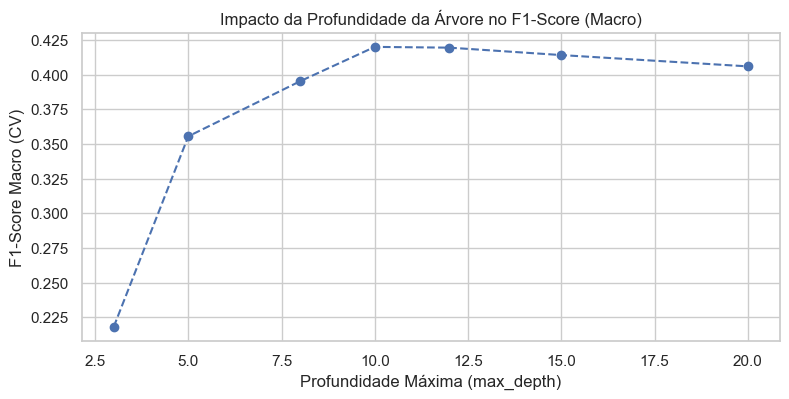

In [24]:
# Testar diferentes profundidades máximas
depths = [3, 5, 8, 10, 12, 15, 20]
mean_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth, random_state=42, class_weight="balanced"
    )
    scores = cross_val_score(
        model, X_train, y_train, cv=skf, scoring="f1_macro"
    )
    mean_scores.append(scores.mean())
    print(f"max_depth={depth:<2} | F1-Score (Macro) Médio: {scores.mean():.4f}")

# Gráfico de evolução da métrica em função da profundidade
plt.figure(figsize=(9, 4))
plt.plot(depths, mean_scores, marker="o", linestyle="--", color="b")
plt.title("Impacto da Profundidade da Árvore no F1-Score (Macro)")
plt.xlabel("Profundidade Máxima (max_depth)")
plt.ylabel("F1-Score Macro (CV)")
plt.show()

## 2.4 Geração do Ficheiro de Submissão Inicial
Treino do modelo final ajustado com a totalidade dos dados de treino e previsão sobre o conjunto de teste para submissão.

In [25]:
# Selecionar a melhor profundidade com base nos resultados anteriores (ex: max_depth=8)
best_depth = depths[np.argmax(mean_scores)]
print(f"Melhor profundidade selecionada: {best_depth}")

final_model = DecisionTreeClassifier(
    max_depth=best_depth, random_state=42, class_weight="balanced"
)
final_model.fit(X_train, y_train)

# Previsões para o conjunto de teste
test_predictions = final_model.predict(X_test)

# Guardar o ficheiro de submissão na pasta 'submissions/'
os.makedirs("../submissions", exist_ok=True)
submission_path = "../submissions/submission_dt_baseline.csv"

submission_df = pd.DataFrame({"RowId": test_df.index, "AGE_RANGE": test_predictions})
submission_df.to_csv(submission_path, index=False)

print(f"Ficheiro de submissão criado com sucesso em: {submission_path}")
print(submission_df.head())

Melhor profundidade selecionada: 10
Ficheiro de submissão criado com sucesso em: ../submissions/submission_dt_baseline.csv
   RowId  AGE_RANGE
0      0          5
1      1          2
2      2         10
3      3          6
4      4         10
